# 📦 Environment Setup for Bathymetry Analysis

To ensure all required dependencies are installed, follow these steps:

## **🔹 Option 1: Using Conda (Recommended)**
If you have **Conda** installed, create a dedicated environment:

```bash
conda create -n ocean_env python=3.9
conda activate ocean_env
conda install -c conda-forge xarray netcdf4 matplotlib cartopy cmocean


# 🌊 Open Oceanography - Bathymetry Analysis
## 📍 Instructions for Downloading ETOPO1 Data
Before running this notebook, you **must manually download the bathymetry dataset**:

1. **Go to**: [NOAA ETOPO1 Bedrock NetCDF](https://www.ngdc.noaa.gov/mgg/global/relief/ETOPO1/data/bedrock/grid_registered/netcdf/)
2. **Download**: `ETOPO1_Bed_g_gmt4.grd.gz`
3. **Extract** the `.grd` file (it should now be `ETOPO1_Bed_g_gmt4.grd`)
4. **Move it** to the same folder as this notebook.

Once the file is in place, run the notebook.


# 🚀 Debugging & Problem-Solving in Programming  

### **Don't Get Frustrated by Errors!**  

If you run into an error, **don't panic**—this is **completely normal** in programming. Even experienced coders spend a huge amount of time debugging!  

### **🔹 How to Troubleshoot Errors**  
1. **Read the error message carefully** – It often tells you exactly what went wrong.
2. **Copy & paste the error into ChatGPT or Google** – Someone has almost certainly solved the same problem before.
3. **Break the problem into smaller parts** – Try running pieces of code separately to isolate the issue.
4. **Ask for help** – If you're stuck, reach out to a coding community or a mentor.

### **🔹 Programming is About Problem-Solving**  
Coding isn’t about writing perfect code on the first try. It’s about:  
✅ **Figuring things out**  
✅ **Testing different solutions**  
✅ **Improving step by step**  

Every bug you fix makes you **a better programmer**. Keep going! 💪  


📂 Loading dataset...


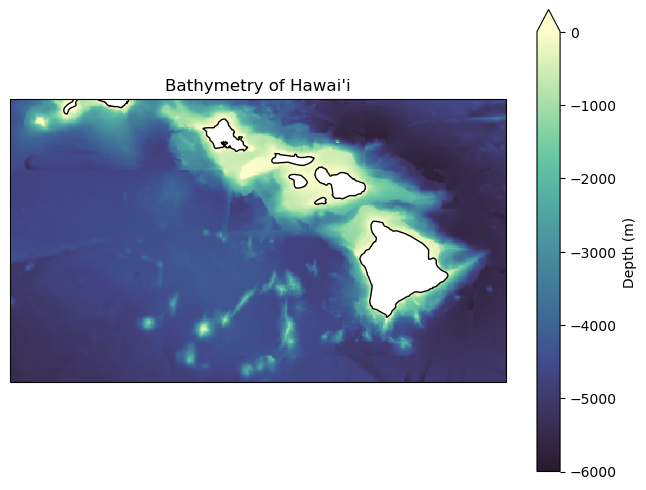

/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


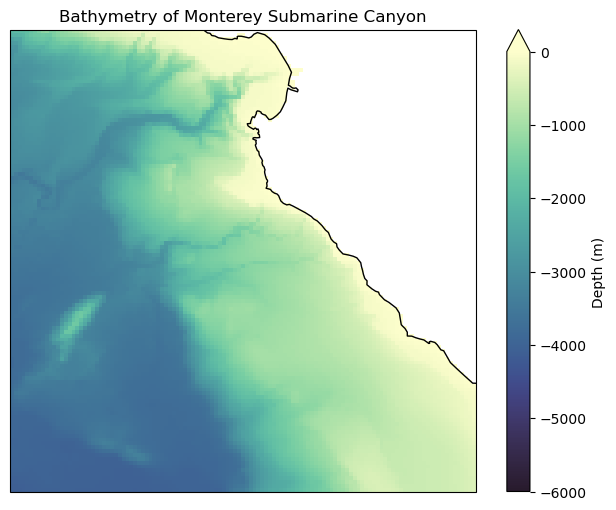

✅ Analysis complete.


In [2]:
import os
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean
import warnings

warnings.filterwarnings("ignore")

# Define file path
LOCAL_FILE = "ETOPO1_Bed_g_gmt4.grd"

# Check if the file exists
if not os.path.exists(LOCAL_FILE):
    raise FileNotFoundError(f"❌ Missing file: {LOCAL_FILE}. Please follow the instructions above.")

# Load the dataset with explicit engine
print("📂 Loading dataset...")
data = xr.open_dataset(LOCAL_FILE, engine="netcdf4")

# Extract Hawai'i and Monterey Submarine Canyon regions
hawaii = data.sel(x=slice(-161, -154), y=slice(18, 22))
monterey = data.sel(x=slice(-123, -121), y=slice(35, 37))

# Mask land (only show ocean depth)
hawaii.z.values[hawaii.z.values > 0] = None
monterey.z.values[monterey.z.values > 0] = None

# Function to plot bathymetry
def plot_bathymetry(region, title):
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    
    im = region.z.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.deep_r,
        vmin=-6000, vmax=0,  
        cbar_kwargs={'label': 'Depth (m)', 'extend': 'max'}  
    )
    
    ax.coastlines()
    ax.set_title(title)
    # Save the figure
    filename = title.replace(" ", "_").lower() + ".png"  # Create filename from title
    plt.savefig(filename, dpi=300, bbox_inches='tight')

    # Show the figure
    plt.show()

# Generate plots for Hawaii and Monterey
plot_bathymetry(hawaii, "Bathymetry of Hawai'i")
plot_bathymetry(monterey, "Bathymetry of Monterey Submarine Canyon")
print("✅ Analysis complete.")

/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/drewburrier/miniconda3/envs/ocean_env/lib/python3.9/site-packages/shapely/predicates.py:798: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


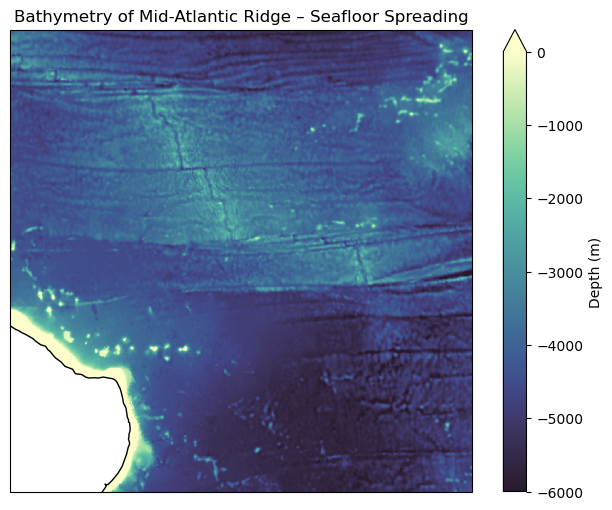

In [3]:
# Extract a visually compelling section of the Mid-Atlantic Ridge
warnings.filterwarnings("ignore")
mid_atlantic_ridge = data.sel(x=slice(-40, -20), y=slice(-10, 10))

# Mask land (only show ocean depth)
mid_atlantic_ridge.z.values[mid_atlantic_ridge.z.values > 0] = None

# Function to plot bathymetry
def plot_bathymetry(region, title):
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    
    im = region.z.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.deep_r,  
        vmin=-6000, vmax=0,  
        cbar_kwargs={'label': 'Depth (m)', 'extend': 'max'}  
    )
    
    ax.coastlines()
    ax.set_title(title)
# Save the figure
    filename = title.replace(" ", "_").lower() + ".png"  # Create filename from title
    plt.savefig(filename, dpi=300, bbox_inches='tight')
# Show the figure
    plt.show()
# Generate plots
plot_bathymetry(mid_atlantic_ridge, "Bathymetry of Mid-Atlantic Ridge – Seafloor Spreading")



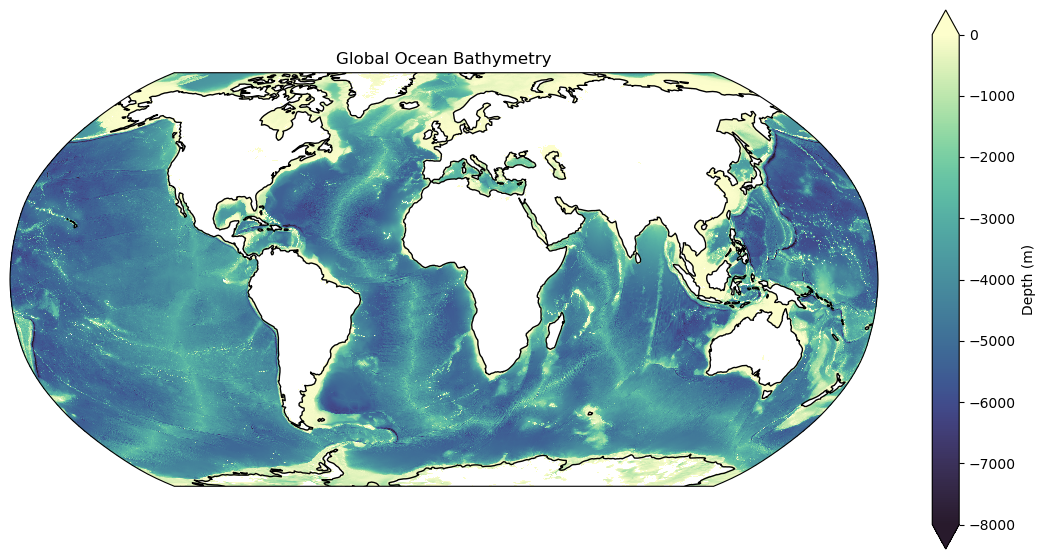

In [4]:

warnings.filterwarnings("ignore")

# Extract the entire dataset for a global view
global_ocean = data.sel(x=slice(-180, 180), y=slice(-80, 80))  # Exclude polar regions to avoid projection distortion

# Mask land (only show ocean depth)
global_ocean.z.values[global_ocean.z.values > 0] = None
# Drop NaN values if needed (ensuring cleaner plots)
# Drop NaN values explicitly from the dataset
global_ocean = global_ocean.dropna(dim="y", how="all").dropna(dim="x", how="all") 

# Function to plot bathymetry
def plot_bathymetry(region, title, projection=ccrs.PlateCarree(), figsize=(12, 6)):
    fig, ax = plt.subplots(figsize=figsize, subplot_kw={'projection': projection})
    
    im = region.z.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.deep_r,  
        vmin=-8000, vmax=0,  
        cbar_kwargs={'label': 'Depth (m)', 'extend': 'both'}
    )
    
    ax.coastlines()
    ax.set_title(title)
    # Save the figure
    filename = title.replace(" ", "_").lower() + ".png"  # Create filename from title
    plt.savefig(filename, dpi=300, bbox_inches='tight')
# Show the figure
    plt.show()

# Generate global ocean plot
plot_bathymetry(global_ocean, "Global Ocean Bathymetry", projection=ccrs.Robinson(), figsize=(14, 7))
